# 암종 분류: 변이 프로파일 EDA 및 모델링
학습/테스트 원본을 보존하고 `artifacts/`에 결과를 저장합니다. macro F1을 주 지표로 가정합니다(공식 평가 지표가 제공되지 않음). 동일한 원본 변이 프로파일은 같은 그룹에 배정합니다. 최종 홀드아웃은 모델 선택에 사용하지 않습니다.
이 노트북과 `data/train.csv`, `data/test.csv`, `data/sample_submission.csv`만 있으면 처음부터 끝까지 실행됩니다. 커널에 numpy, pandas, scipy, scikit-learn, matplotlib, IPython, threadpoolctl, cloudpickle이 설치되어 있어야 합니다. 

In [1]:
import os
os.environ['MPLCONFIGDIR'] = str(__import__('pathlib').Path('.mplconfig').resolve())
os.environ['OMP_NUM_THREADS'] = '2'
from pathlib import Path
import json, pickle, cloudpickle, hashlib, sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from threadpoolctl import threadpool_limits
"""Serializable, train-fold-fitted genomic mutation feature extraction."""
import re
import numpy as np
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction import DictVectorizer

GROUPS = {
 'p53_cellcycle': 'TP53 RB1 CDKN2A CDKN2B CDK4 CDK6 CCND1 ATM CHEK2'.split(),
 'rtk_ras_mapk': 'EGFR ERBB2 ERBB3 KRAS NRAS HRAS BRAF NF1 MAP2K1 MAP2K2 KIT PDGFRA FGFR2 FGFR3'.split(),
 'pi3k_mtor': 'PIK3CA PIK3R1 PTEN AKT1 MTOR TSC1 TSC2 STK11'.split(),
 'dna_repair': 'BRCA1 BRCA2 PALB2 ATM ATR CHEK2 MLH1 MSH2 MSH6 PMS2 POLE POLD1'.split(),
 'chromatin': 'ARID1A ARID1B ARID2 PBRM1 SMARCA4 BAP1 SETD2 KMT2A KMT2C KMT2D ATRX'.split(),
 'wnt': 'APC CTNNB1 AXIN1 AXIN2 RNF43'.split(),
 'metabolism': 'IDH1 IDH2 SDHB SDHC SDHD FH VHL'.split(),
}

def kind(token):
 if 'fs' in token.lower(): return 'frameshift'
 if '*' in token: return 'stop'
 if 'del' in token.lower(): return 'deletion'
 if 'ins' in token.lower(): return 'insertion'
 m = re.fullmatch(r'([A-Z])(\d+)([A-Z])', token)
 if m: return 'synonymous' if m[1] == m[3] else 'substitution'
 return 'other'

class MutationFeatures(BaseEstimator, TransformerMixin):
 def __init__(self, mode='full', min_df=3):
  self.mode = mode
  self.min_df = min_df

 def dictionaries(self, X):
  genes = list(X.columns)
  for row in X.itertuples(index=False, name=None):
   d = {}; counts = {}; burden = 0; events = 0; positions = []
   changed = set()
   for gene, value in zip(genes, row):
    if value is None or str(value) in ('nan', '', '<NA>'):
     d['missing:' + gene] = 1; continue
    if value == 'WT': continue
    changed.add(gene); burden += 1; d['gene:' + gene] = 1
    if self.mode == 'binary': continue
    tokens = str(value).split()
    for token in tokens:
     events += 1; typ = kind(token); counts[typ] = counts.get(typ, 0) + 1
     d['variant:' + gene + ':' + token] = 1
     d['type:' + gene + ':' + typ] = 1
     m = re.search(r'\d+', token)
     if m:
      position = int(m[0]); positions.append(position)
      d['position:' + gene + ':' + str(position)] = 1
   if self.mode == 'full':
    d['numeric:log_mutated_genes'] = np.log1p(burden)
    d['numeric:log_events'] = np.log1p(events)
    d['numeric:multi_event_excess'] = np.log1p(max(0, events-burden))
    for typ in ['frameshift','stop','deletion','insertion','synonymous','substitution','other']:
     d['numeric:log_' + typ] = np.log1p(counts.get(typ,0))
     d['numeric:fraction_' + typ] = counts.get(typ,0)/max(events,1)
    d['numeric:log_mean_position'] = np.log1p(np.mean(positions)) if positions else 0.
    for name, members in GROUPS.items():
     d['module:' + name] = np.log1p(len(changed.intersection(members)))
   yield d

 def fit(self, X, y=None):
  self.genes_ = list(X.columns)
  self.vectorizer_ = DictVectorizer(dtype=np.float32)
  matrix = self.vectorizer_.fit_transform(self.dictionaries(X))
  names = self.vectorizer_.get_feature_names_out()
  self.keep_ = (np.asarray((matrix != 0).sum(axis=0)).ravel() >= self.min_df) | np.array([s.startswith(('numeric:', 'module:')) for s in names])
  self.feature_names_ = names[self.keep_]
  return self

 def transform(self, X):
  missing = set(self.genes_) - set(X.columns)
  if missing: raise ValueError('Missing gene columns: ' + str(sorted(missing)[:10]))
  return sparse.csr_matrix(self.vectorizer_.transform(self.dictionaries(X[self.genes_]))[:, self.keep_])

 def get_feature_names_out(self, input_features=None): return self.feature_names_

threadpool_limits(2)
OUT = Path('artifacts'); OUT.mkdir(exist_ok=True)
SEED=42
train=pd.read_csv('data/train.csv'); test=pd.read_csv('data/test.csv'); sample=pd.read_csv('data/sample_submission.csv')
genes=[c for c in train if c not in ['ID','SUBCLASS']]
assert list(test.columns)==['ID']+genes
assert train.ID.is_unique and test.ID.is_unique
assert list(sample.ID)==list(test.ID)
X=train[genes]; y=train.SUBCLASS
groups=pd.util.hash_pandas_object(X, index=False).values
print('Train:',train.shape,'Test:',test.shape,'Genes:',len(genes),'Classes:',y.nunique())
print('Missing:', int(X.isna().sum().sum()), 'Test missing:',int(test[genes].isna().sum().sum()))

Train: (6201, 4386) Test: (2546, 4385) Genes: 4384 Classes: 26


Missing: 0 Test missing: 237


## 1. EDA: 클래스, 희소성, 분포 차이, 중복
WT는 기준형 표기이며 측정된 유전자 내 비-WT 비율을 계산합니다. 이 변이량은 엑솜 크기/커버리지 정보가 없는 데이터의 지표이므로 임상적 TMB가 아닙니다. 결측값은 WT와 구분합니다.

,SUBCLASS,count
0,BRCA,786
1,KIPAN,515
2,GBMLGG,461
3,STES,379
4,KIRC,334
5,THCA,324
6,SKCM,276
7,PRAD,266
8,OV,253
9,LGG,229


,count,mean,median,min,max
SUBCLASS,,,,,
ACC,72,39.430556,24.0,10,396
BLCA,104,70.490385,54.0,3,382
BRCA,786,17.437659,9.0,0,853
CESC,155,44.129032,20.0,0,480
COAD,223,73.121076,23.0,5,1631
DLBC,38,67.421053,30.0,3,704
GBMLGG,461,12.535792,11.0,0,121
HNSC,223,40.569507,31.0,1,386
KIPAN,515,16.042718,15.0,0,246


,gene,train_mutated,train_rate,test_mutated,test_rate,train_unique,missing,test_minus_train_rate
4107,TP53,1770,0.285438,1051,0.412804,664,0,0.127367
2977,PIK3CA,686,0.110627,343,0.134721,208,0,0.024094
3469,RYR2,643,0.103693,361,0.141791,621,0,0.038098
3907,SYNE1,642,0.103532,444,0.174391,613,0,0.070860
2857,PCLO,593,0.095630,351,0.137863,567,0,0.042234
3468,RYR1,473,0.076278,326,0.128044,455,0,0.051766
3804,SPTA1,461,0.074343,240,0.094266,440,0,0.019923
2151,KMT2D,451,0.072730,492,0.193244,418,0,0.120514
1888,IDH1,441,0.071118,124,0.048704,34,0,-0.022414
474,BRAF,438,0.070634,230,0.090338,93,0,0.019704


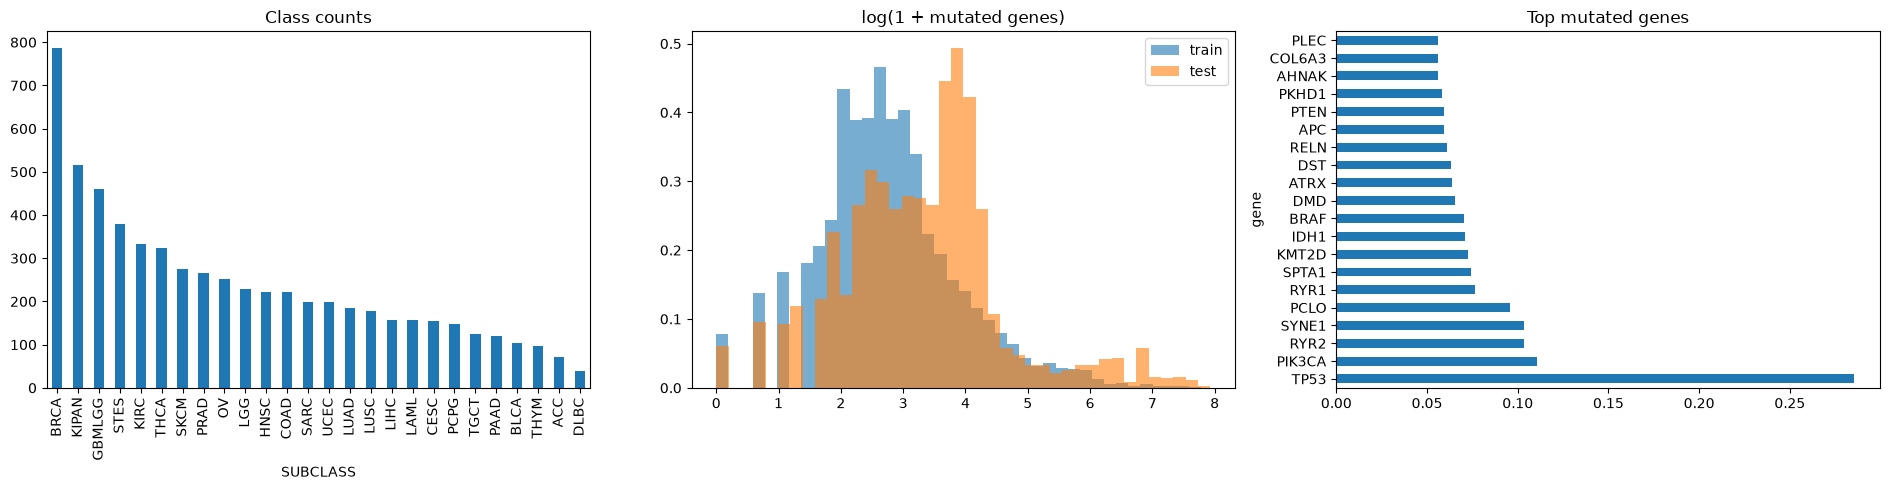

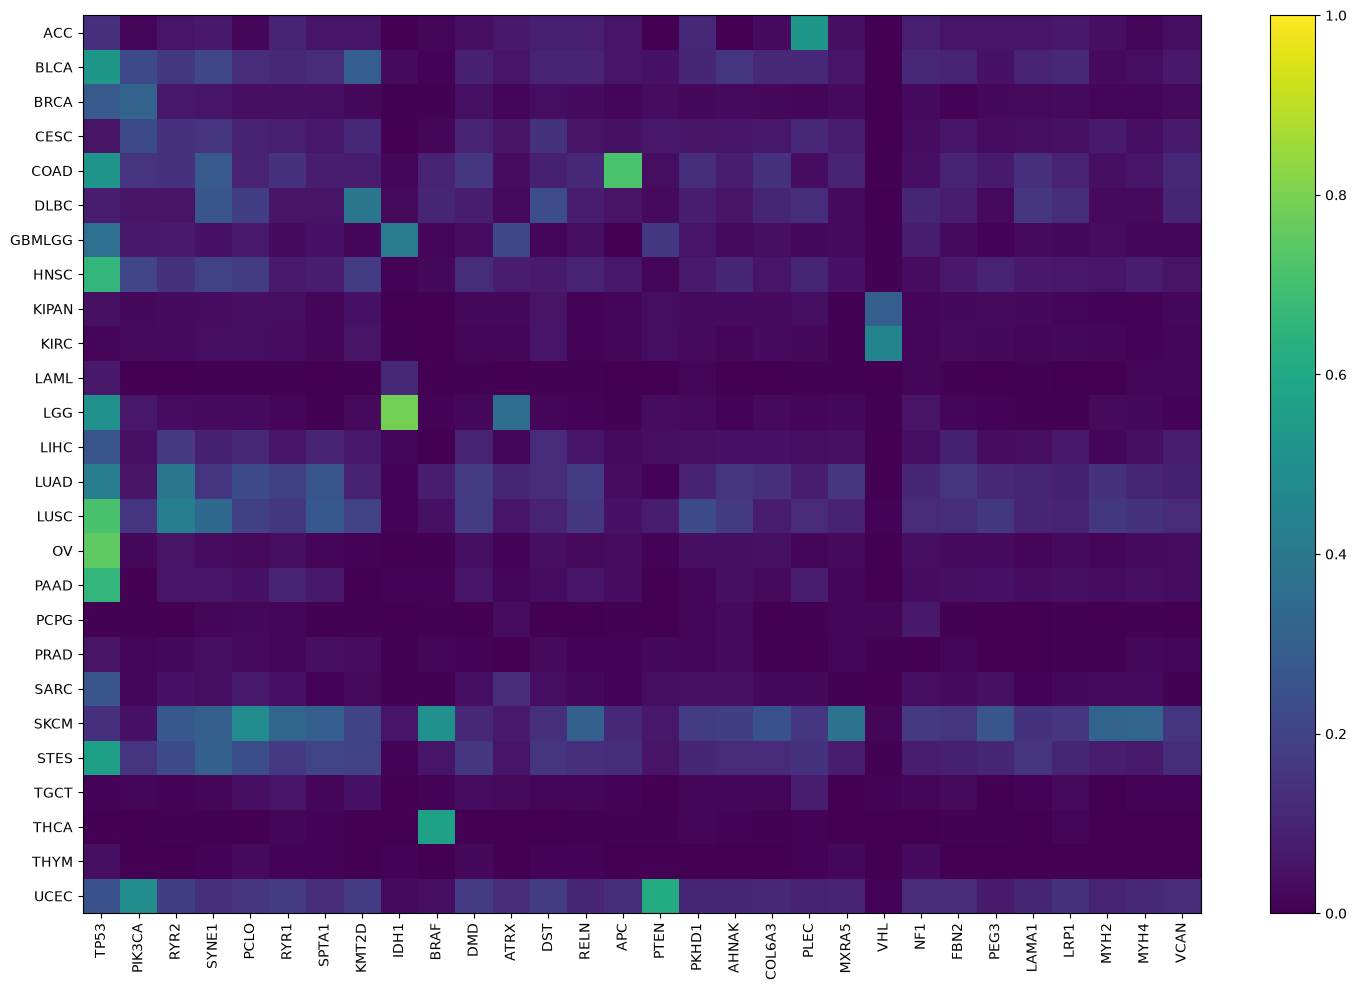

{'train_rows': 6201, 'test_rows': 2546, 'genes': 4384, 'classes': 26, 'missing_train': 0, 'missing_test': 237, 'WT_fraction': 0.9919480773056383, 'constant_genes': 154, 'duplicate_profile_rows': 1016, 'conflicting_profile_groups': 447, 'test_profiles_in_train': 266, 'burden_train': {'count': 6201.0, 'mean': 35.29962909208192, 'std': 100.77637915217879, 'min': 0.0, '25%': 7.0, '50%': 14.0, '75%': 27.0, 'max': 2393.0}, 'burden_test': {'count': 2546.0, 'mean': 78.13432835820896, 'std': 213.96453450837973, 'min': 0.0, '25%': 11.0, '50%': 28.0, '75%': 52.0, 'max': 2784.0}}


In [2]:
binary=(X.ne('WT') & X.notna()); tbinary=(test[genes].ne('WT') & test[genes].notna())
burden=binary.sum(axis=1); tburden=tbinary.sum(axis=1)
classes=y.value_counts().rename_axis('SUBCLASS').reset_index(name='count')
classes.to_csv(OUT/'class_distribution.csv',index=False)
gene_stats=pd.DataFrame({'gene':genes,'train_mutated':binary.sum().values,'train_rate':binary.mean().values,'test_mutated':tbinary.sum().values,'test_rate':tbinary.mean().values,'train_unique':X.nunique().values,'missing':X.isna().sum().values})
gene_stats['test_minus_train_rate']=gene_stats.test_rate-gene_stats.train_rate
gene_stats.to_csv(OUT/'gene_dictionary.csv',index=False)
burden_table=pd.DataFrame({'SUBCLASS':y,'burden':burden}).groupby('SUBCLASS').burden.agg(['count','mean','median','min','max'])
burden_table.to_csv(OUT/'burden_by_class.csv')
duplicate_rows=int(pd.Series(groups).duplicated(keep=False).sum())
conflicts=int(pd.DataFrame({'g':groups,'y':y}).groupby('g').y.nunique().gt(1).sum())
test_groups=pd.util.hash_pandas_object(test[genes],index=False).values
overlap=int(np.isin(test_groups,groups).sum())
eda={'train_rows':len(train),'test_rows':len(test),'genes':len(genes),'classes':y.nunique(),'missing_train':int(X.isna().sum().sum()),'missing_test':int(test[genes].isna().sum().sum()),'WT_fraction':float(X.eq('WT').to_numpy().mean()),'constant_genes':int(X.nunique().eq(1).sum()),'duplicate_profile_rows':duplicate_rows,'conflicting_profile_groups':conflicts,'test_profiles_in_train':overlap,'burden_train':burden.describe().to_dict(),'burden_test':tburden.describe().to_dict()}
(OUT/'eda_summary.json').write_text(json.dumps(eda,indent=2))
display(classes,burden_table, gene_stats.nlargest(20,'train_rate'))
fig,axes=plt.subplots(1,3,figsize=(19,5))
classes.plot.bar(x='SUBCLASS',y='count',ax=axes[0],legend=False,title='Class counts')
axes[1].hist(np.log1p(burden),bins=40,alpha=.6,label='train',density=True); axes[1].hist(np.log1p(tburden),bins=40,alpha=.6,label='test',density=True); axes[1].legend(); axes[1].set_title('log(1 + mutated genes)')
gene_stats.nlargest(20,'train_rate').plot.barh(x='gene',y='train_rate',ax=axes[2],legend=False,title='Top mutated genes')
plt.tight_layout(); plt.savefig(OUT/'eda.png',dpi=150); plt.show()
rates=binary.groupby(y).mean()
rates.to_csv(OUT/'gene_class_mutation_rates.csv')
top=gene_stats.nlargest(30,'train_rate').gene
fig,ax=plt.subplots(figsize=(15,10)); im=ax.imshow(rates[top],aspect='auto',vmin=0,vmax=1); ax.set_xticks(range(len(top)),top,rotation=90); ax.set_yticks(range(len(rates)),rates.index); fig.colorbar(im); plt.tight_layout(); plt.savefig(OUT/'class_gene_heatmap.png',dpi=150); plt.show()
print(eda)

## 2. 파생변수와 누수 방지
- binary: 유전자별 비-WT 유무.
- tokens: binary + 유전자/정확한 변이 + 유전자/아미노산 위치 + 유전자/변이 유형.
- full: tokens + log 변이 유전자 수/이벤트 수/복수 이벤트 초과량 + 유형별 log 개수와 비율 + log 평균 위치 + 7개 수작업 유전자 그룹의 log 변이 수.
공백으로 여러 변이를 나누며 정규식으로 확정할 수 없는 표기는 other로 남깁니다. 위치는 아미노산 표기의 숫자일 뿐 유전체 좌표가 아닙니다. 그룹은 탐색적 집계이며 경로 활성도를 의미하지 않습니다. 빈도 필터(min_df=3)는 각 학습 폴드만으로 적합합니다. ID와 SUBCLASS는 입력에서 제외합니다.

In [3]:
outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
dev_idx,hold_idx=next(outer.split(X,y,groups))
Xd=X.iloc[dev_idx]; yd=y.iloc[dev_idx]; gd=groups[dev_idx]
folds=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+1).split(Xd,yd,gd))
assert not set(groups[dev_idx]) & set(groups[hold_idx])
assert set(yd)==set(y.iloc[hold_idx])==set(y)
pd.DataFrame({'ID':train.ID,'split':np.where(np.isin(np.arange(len(train)),hold_idx),'holdout','development'),'profile_group':groups.astype(str)}).to_csv(OUT/'split_manifest.csv',index=False)
labels=np.sort(y.unique())
configs={
 'dummy':('binary',DummyClassifier(strategy='prior')),
 'binary_lr':('binary',LogisticRegression(C=1,max_iter=2000)),
 'tokens_lr':('tokens',LogisticRegression(C=1,max_iter=2000)),
 'full_lr_c025':('full',LogisticRegression(C=.25,max_iter=2000)),
 'full_lr_c1':('full',LogisticRegression(C=1,max_iter=2000)),
 'full_lr_c4':('full',LogisticRegression(C=4,max_iter=2000)),
 'full_lr_balanced':('full',LogisticRegression(C=1,max_iter=2000,class_weight='balanced')),
 'full_nb':('full',ComplementNB(alpha=.5)),
 'full_sgd':('full',SGDClassifier(loss='log_loss',alpha=.0001,max_iter=1500,tol=1e-4,random_state=SEED,average=True)),
 'full_extratrees':('full',ExtraTreesClassifier(n_estimators=300,min_samples_leaf=2,max_features=.15,class_weight='balanced',n_jobs=2,random_state=SEED)),
}
results=[]; oof={name:np.zeros((len(Xd),len(labels))) for name in configs}
for mode in ['binary','tokens','full']:
 for fold,(tr,va) in enumerate(folds):
  extractor=MutationFeatures(mode=mode).fit(Xd.iloc[tr])
  a=extractor.transform(Xd.iloc[tr]); b=extractor.transform(Xd.iloc[va])
  for name,(m,est) in configs.items():
   if m!=mode: continue
   fitted=clone(est).fit(a,yd.iloc[tr]); p=fitted.predict_proba(b)
   assert np.array_equal(fitted.classes_,labels)
   oof[name][va]=p
   pred=labels[p.argmax(axis=1)]
   score=f1_score(yd.iloc[va],pred,average='macro',zero_division=0)
   results.append({'model':name,'fold':fold,'macro_f1':score,'accuracy':accuracy_score(yd.iloc[va],pred),'features':a.shape[1]})
   print(name,fold,round(score,5),flush=True)
fold_results=pd.DataFrame(results); fold_results.to_csv(OUT/'cv_folds.csv',index=False)
ranking=fold_results.groupby('model').agg(macro_f1=('macro_f1','mean'),std=('macro_f1','std'),accuracy=('accuracy','mean')).sort_values('macro_f1',ascending=False)
display(ranking)
best=ranking.index[0]
# Only pre-specified equal-probability averaging of the two strongest individual models.
top2=list(ranking.drop(index='dummy').index[:2]); blend=sum(oof[n] for n in top2)/2
blend_scores=[f1_score(yd.iloc[va],labels[blend[va].argmax(axis=1)],average='macro',zero_division=0) for _,va in folds]
ranking.loc['blend_top2']=[np.mean(blend_scores),np.std(blend_scores,ddof=1),accuracy_score(yd,labels[blend.argmax(axis=1)])]
ranking=ranking.sort_values('macro_f1',ascending=False); ranking.to_csv(OUT/'model_comparison.csv')
selected=top2 if ranking.index[0]=='blend_top2' else [ranking.index[0]]
print('Selected from development CV:',selected); display(ranking)

dummy 0 0.00863


binary_lr 0 0.31102


dummy 1 0.00867


binary_lr 1 0.30879


dummy 2 0.00867


binary_lr 2 0.31363


... (23 outputs left out)

full_extratrees 2 0.38848


,macro_f1,std,accuracy
model,,,
full_lr_balanced,0.392232,0.004162,0.421572
full_extratrees,0.390090,0.008447,0.397580
full_lr_c025,0.375485,0.008120,0.430040
full_lr_c1,0.373989,0.003456,0.421572
full_lr_c4,0.365154,0.006171,0.408064
full_sgd,0.358529,0.005440,0.413509
tokens_lr,0.330882,0.002752,0.387096
binary_lr,0.311145,0.002421,0.372176
full_nb,0.285370,0.012652,0.361694


Selected from development CV: ['full_lr_balanced', 'full_extratrees']


,macro_f1,std,accuracy
model,,,
blend_top2,0.418332,0.006658,0.436089
full_lr_balanced,0.392232,0.004162,0.421572
full_extratrees,0.390090,0.008447,0.397580
full_lr_c025,0.375485,0.008120,0.430040
full_lr_c1,0.373989,0.003456,0.421572
full_lr_c4,0.365154,0.006171,0.408064
full_sgd,0.358529,0.005440,0.413509
tokens_lr,0.330882,0.002752,0.387096
binary_lr,0.311145,0.002421,0.372176


## 3. 잠금 홀드아웃 평가
위의 선택을 고정한 뒤 평가합니다. 최초 max_iter=400 실행의 수렴 경고를 보완하기 위해, 동일 분할과 후보에서 반복 상한만 2,000으로 늘려 재실행했습니다. 초기 결과는 artifacts/initial_maxiter400에 보관했습니다. 홀드아웃은 수렴 보완 후 재평가되었으며, 점수를 보고 C/가중치/변수/앙상블 구성을 조정하지 않았습니다. 표본 수가 적은 클래스의 F1은 변동성이 큽니다. macro F1 및 정확도, weighted F1, 클래스별 precision/recall/F1, 혼동행렬을 저장합니다.

{'macro_f1': 0.4237006861200228, 'weighted_f1': 0.42912369013681145, 'accuracy': 0.42788074133763093, 'n': 1241} conditional stratified bootstrap 95% CI: [0.392080419581428, 0.44993516219213764]


,precision,recall,f1-score,support
ACC,0.923077,0.857143,0.888889,14.000000
BLCA,0.666667,0.300000,0.413793,20.000000
BRCA,0.553957,0.490446,0.520270,157.000000
CESC,0.318182,0.225806,0.264151,31.000000
COAD,0.745098,0.863636,0.800000,44.000000
DLBC,1.000000,0.571429,0.727273,7.000000
GBMLGG,0.617021,0.315217,0.417266,92.000000
HNSC,0.419355,0.295455,0.346667,44.000000
KIPAN,0.315385,0.398058,0.351931,103.000000
KIRC,0.352941,0.268657,0.305085,67.000000


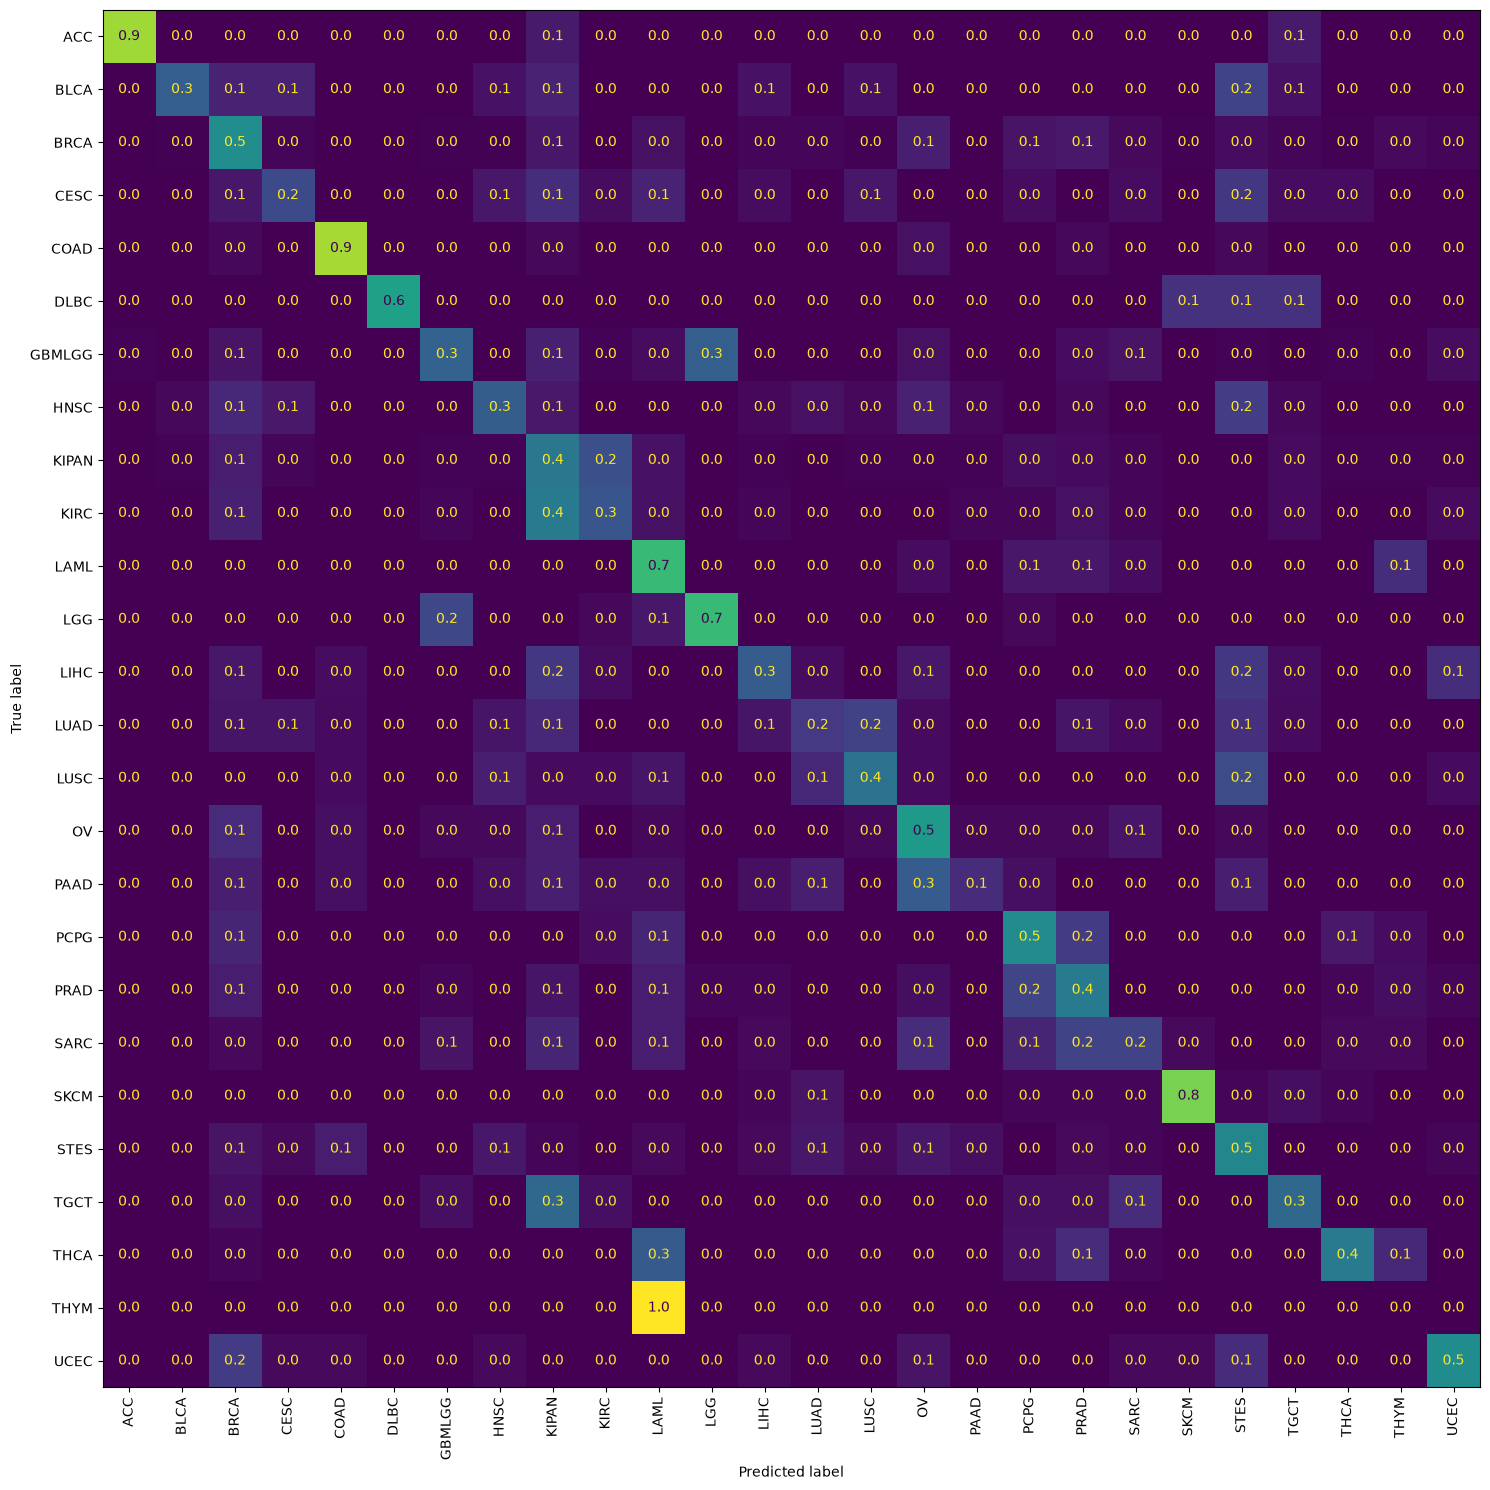

In [4]:
def fit_models(indices):
 models=[]
 for name in selected:
  mode,est=configs[name]
  pipe=Pipeline([('features',MutationFeatures(mode=mode)),('classifier',clone(est))])
  pipe.fit(X.iloc[indices],y.iloc[indices]); models.append(pipe)
 return models
def probability(models, frame): return sum(m.predict_proba(frame) for m in models)/len(models)
dev_models=fit_models(dev_idx)
hp=probability(dev_models,X.iloc[hold_idx]); pred=labels[hp.argmax(axis=1)]
metrics={'macro_f1':f1_score(y.iloc[hold_idx],pred,average='macro',zero_division=0),'weighted_f1':f1_score(y.iloc[hold_idx],pred,average='weighted',zero_division=0),'accuracy':accuracy_score(y.iloc[hold_idx],pred),'n':len(hold_idx)}
report=pd.DataFrame(classification_report(y.iloc[hold_idx],pred,output_dict=True,zero_division=0)).T
report.to_csv(OUT/'holdout_classification_report.csv'); (OUT/'holdout_metrics.json').write_text(json.dumps(metrics,indent=2))
pd.DataFrame({'ID':train.ID.iloc[hold_idx].values,'true':y.iloc[hold_idx].values,'prediction':pred,'confidence':hp.max(axis=1)}).to_csv(OUT/'holdout_predictions.csv',index=False)
rng=np.random.default_rng(SEED); boot=[]
hy=y.iloc[hold_idx].to_numpy()
for _ in range(500):
 ix=np.concatenate([rng.choice(np.flatnonzero(hy==c),size=(hy==c).sum(),replace=True) for c in labels])
 boot.append(f1_score(hy[ix],pred[ix],labels=labels,average='macro',zero_division=0))
ci=np.quantile(boot,[.025,.975]).tolist(); print(metrics,'conditional stratified bootstrap 95% CI:',ci)
display(report)
fig,ax=plt.subplots(figsize=(15,15)); ConfusionMatrixDisplay.from_predictions(hy,pred,labels=labels,normalize='true',xticks_rotation=90,ax=ax,values_format='.1f',colorbar=False); plt.tight_layout(); plt.savefig(OUT/'holdout_confusion.png',dpi=150); plt.show()

## 4. 전체 재학습, 모델 피클, 제출 파일, 변수 해석
피클은 전처리기와 분류기, 클래스/유전자 순서와 설정을 포함합니다. 학습용 전체 행으로 재학습하므로 저장 모델 자체의 성능을 홀드아웃 수치로 직접 재평가하지 않습니다. 학습/테스트 중복 프로파일을 정답 매핑에 이용하지 않습니다.

In [5]:
final_models=fit_models(np.arange(len(train)))
bundle={'models':final_models,'classes':labels,'genes':genes,'selected':selected,'seed':SEED,'holdout_metrics':metrics,'python':sys.version}
with (OUT/'cancer_model.pkl').open('wb') as f: cloudpickle.dump(bundle,f,protocol=pickle.HIGHEST_PROTOCOL)
with (OUT/'cancer_model.pkl').open('rb') as f: loaded=pickle.load(f)
tp=probability(loaded['models'],test[genes]); expected=probability(final_models,test[genes].iloc[:10])
assert np.allclose(tp[:10],expected)
assert np.isfinite(tp).all() and np.allclose(tp.sum(axis=1),1)
submission=sample.copy(); submission['SUBCLASS']=labels[tp.argmax(axis=1)]
assert submission.ID.equals(sample.ID) and submission.SUBCLASS.isin(y.unique()).all()
submission.to_csv(OUT/'submission.csv',index=False)
pd.DataFrame(tp,columns=labels,index=test.ID).to_csv(OUT/'test_probabilities.csv')
selected_feature_tables=[]
for name,pipe in zip(selected,final_models):
 names=pipe['features'].get_feature_names_out(); est=pipe['classifier']
 table=pd.DataFrame({'feature':names,'family':[n.split(':')[0] for n in names],'model':name})
 if hasattr(est,'coef_'):
  table['importance']=np.abs(est.coef_).mean(axis=0)
  table['strongest_class']=est.classes_[est.coef_.argmax(axis=0)]
  top_rows=[]
  for c,coef in zip(est.classes_,est.coef_):
   ix=np.argsort(coef)[-20:][::-1]
   top_rows.extend({'SUBCLASS':c,'feature':names[i],'coefficient':coef[i]} for i in ix)
  pd.DataFrame(top_rows).to_csv(OUT/(name+'_class_coefficients.csv'),index=False)
 elif hasattr(est,'feature_importances_'): table['importance']=est.feature_importances_
 else: table['importance']=np.nan
 table.to_csv(OUT/(name+'_features.csv'),index=False); selected_feature_tables.append(table)
features=pd.concat(selected_feature_tables,ignore_index=True); features.to_csv(OUT/'final_features.csv',index=False)
display(features.sort_values('importance',ascending=False).head(40))
print('MODEL SAVED:', (OUT/'cancer_model.pkl').resolve()); print('Saved model bytes:',(OUT/'cancer_model.pkl').stat().st_size)
from IPython.display import FileLink
display(FileLink(str(OUT/'cancer_model.pkl')))
print(submission.SUBCLASS.value_counts())

,feature,family,model,importance,strongest_class
3942,gene:TP53,gene,full_lr_balanced,0.579265,OV
4217,module:metabolism,module,full_lr_balanced,0.399011,KIRC
4114,gene:VHL,gene,full_lr_balanced,0.395447,KIRC
4239,numeric:multi_event_excess,numeric,full_lr_balanced,0.395382,CESC
4231,numeric:log_frameshift,numeric,full_lr_balanced,0.392180,KIPAN
4218,module:p53_cellcycle,module,full_lr_balanced,0.392030,PAAD
4237,numeric:log_substitution,numeric,full_lr_balanced,0.374130,LUSC
4234,numeric:log_mutated_genes,numeric,full_lr_balanced,0.350769,LUSC
15748,type:PIK3CA:substitution,type,full_lr_balanced,0.327532,UCEC
4238,numeric:log_synonymous,numeric,full_lr_balanced,0.317332,ACC


MODEL SAVED: /Users/mac/project/cancer_project/artifacts/cancer_model.pkl
Saved model bytes: 360238477


/Users/mac/project/cancer_project/artifacts/cancer_model.pkl

SUBCLASS
STES      415
BRCA      266
KIPAN     226
COAD      190
CESC      136
OV        131
PRAD      106
BLCA      100
SKCM       98
GBMLGG     91
KIRC       81
UCEC       75
PCPG       74
LUAD       68
THCA       65
LUSC       61
LGG        60
THYM       54
SARC       54
HNSC       46
LIHC       41
LAML       31
TGCT       24
ACC        23
DLBC       15
PAAD       15
Name: count, dtype: int64


In [6]:
# Generate the detailed report from actual run outputs, not hypothetical numbers.
from pathlib import Path
import json

def table(df, index=True):
    data=df.reset_index() if index else df
    cols=list(data.columns)
    rows=['| '+' | '.join(map(str,cols))+' |','| '+' | '.join(['---']*len(cols))+' |']
    for values in data.itertuples(index=False,name=None):
        rows.append('| '+' | '.join(f'{v:.5f}' if isinstance(v,float) else str(v).replace('|','/') for v in values)+' |')
    return '\n'.join(rows)

def write_report(train,test,eda,classes,gene_stats,burden_table,ranking,metrics,ci,selected,features,report,groups):
    import pandas as pd
    from collections import Counter
    rates=pd.read_csv('artifacts/gene_class_mutation_rates.csv',index_col=0)
    direct_counts=Counter(n.split(':')[1] for n in features.feature if n.split(':')[0] in {'gene','variant','position','type','missing'})
    records=[]
    for row in gene_stats.itertuples(index=False):
        gene=row.gene
        records.append({'gene':gene,'train_n':row.train_mutated,'train_rate':row.train_rate,'test_rate':row.test_rate,'most_frequent_class':rates[gene].idxmax(),'class_rate':rates[gene].max(),'final_feature_count':direct_counts[gene],'modules':', '.join(k for k,v in groups.items() if gene in v) or '-'})
    dictionary=pd.DataFrame(records)
    Path('gene_dictionary.md').write_text('''# 전체 유전자 컬럼 사전\n\n각 행은 원본 유전자 컬럼 하나다. 값은 WT/변이 표기이며, gene·variant·position·type 파생변수의 의미는 [분석 보고서](analysis_report.md)의 사전을 따른다. train_n은 변이 환자 수, train_rate/test_rate는 변이 비율, most_frequent_class와 class_rate는 학습 내 관측 비율이 가장 큰 암종과 그 비율이다(인과성/진단 특이도 아님). 모든 클래스 비율이 0이면 첫 클래스가 표시된다. final_feature_count는 최종 모델들에서 해당 유전자에 직접 연결된 변수 수의 합이다. 모듈 합산에만 쓰인 경우는 이 개수에 포함되지 않으며 modules 열에 표시된다. 비율 차이는 출처/클래스 구성 차이와 표본 변동을 반영할 수 있다. 유전자 기능 주석은 원본에 없으므로 추정하지 않았다.\n\n'''+table(dictionary,False))
    family=features.groupby(['model','family']).size().rename('feature_count').reset_index()
    top=features.sort_values(['model','importance'],ascending=[True,False]).groupby('model',sort=False).head(25)
    low=report.loc[classes.SUBCLASS].sort_values('f1-score').head(10)
    predictions=pd.read_csv('artifacts/holdout_predictions.csv')
    confusion_pairs=predictions[predictions.true!=predictions.prediction].groupby(['true','prediction']).size().rename('count').reset_index().sort_values('count',ascending=False).head(20)
    text=f'''# 암환자 유전체 변이 기반 암종 분류 분석 보고서

## 1. 목적과 결과
유전자별 WT/변이 문자열만으로 데이터셋의 SUBCLASS 26개를 예측했다. 공식 평가 지표가 제공되지 않아 macro F1을 선택 기준으로 삼았다. 최고 성능의 전역적 보장을 의미하는 “최적”이 아니라, 아래 명시된 후보와 검증 범위에서 가장 좋은 구성을 선택했다.

- 선택된 모델: {', '.join(selected)}. 둘이면 각 모델 확률을 0.5씩 평균한다.
- 개발 세트 3-fold 최고 평균 macro F1: {ranking.iloc[0].macro_f1:.5f}.
- 모델 선택에 사용하지 않은 홀드아웃 {metrics['n']}명: macro F1 **{metrics['macro_f1']:.5f}**, accuracy **{metrics['accuracy']:.5f}**, weighted F1 **{metrics['weighted_f1']:.5f}**.
- 고정된 홀드아웃 예측의 클래스별 층화 bootstrap 500회 조건부 95% 구간: [{ci[0]:.5f}, {ci[1]:.5f}]. 모델 재학습 변동과 데이터 출처 차이를 반영하지 않는다.
- 최종 모델은 전체 학습 데이터로 재학습했고 피클 직렬화 후 재로딩 예측 일치를 확인했다. 테스트 정답이 없어 테스트 성능과 리더보드 성능은 알 수 없다.

## 2. 데이터 스키마와 정합성
실제 파일 기준 train {len(train):,}행 × {train.shape[1]:,}열, test {len(test):,}행 × {test.shape[1]:,}열이다. 문제 설명의 6,199 유전자와 다르게 실제 유전자는 **{eda['genes']:,}개**다. train과 test의 유전자 이름 및 순서, 제출 ID 순서를 검증했다. 원본은 변경하지 않았다.

| 컬럼 | 의미 | 처리 및 이유 |
| --- | --- | --- |
| ID | 샘플 식별자 | 유일성과 제출 정렬 검증에만 사용. 모델 제외 |
| SUBCLASS | 학습 정답, 문자열 26종 | 목적변수. 입력 변수에서 제외 |
| 유전자 심볼 4,384개 | 해당 유전자의 WT 또는 변이 표기 문자열 | 변이 유무/토큰/위치/유형으로 변환 |
| WT | 기준형으로 표기된 셀 | 변이 특성 0. 결측과 별도로 처리 |
| 결측 | 미기록 셀 | missing:유전자 변수로 분리. 관측되지 않으면 빈도 필터로 제외 |

본 파일에는 나이, 성별, 병기, 조직, 변이 대립유전자 빈도, 시퀀싱 깊이, 표본 출처/배치 정보가 없다. 아미노산 표기만으로 유전자 기능 손상 여부나 원인 변이를 확정하지 않는다. 각 유전자 컬럼의 통계와 의미는 `artifacts/gene_dictionary.csv`에 한 행씩 제공한다: gene=원본 컬럼명, train_mutated/test_mutated=비-WT 환자 수, train_rate/test_rate=비-WT 비율, train_unique=훈련값 종류 수, missing=훈련 결측 수, test_minus_train_rate=테스트-학습 비율 차이. 이 파일은 4,384개 모든 컬럼을 포함한다. 유전자별 생물학적 기능 주석은 제공 데이터에 없으므로 임의로 작성하지 않았다.

학습에는 결측이 없어 최종 사전에 missing:G 변수가 없다. 테스트 결측은 파서에서 분리하지만 미등록 특성으로 무시되며 변이 이벤트로 세지 않는다. 따라서 이번 최종 모델은 테스트 결측의 불확실성을 별도로 학습하지 못하고, 해당 셀에서 알려진 변이 특성은 WT처럼 0이 되는 한계가 있다.

## 3. EDA 결과
- 학습 WT 셀 비율: {eda['WT_fraction']:.4%}. 매우 희소하므로 CSR 희소행렬로 학습한다.
- 학습 결측 {eda['missing_train']}, 테스트 결측 {eda['missing_test']}개.
- 학습 상수 유전자 {eda['constant_genes']}개. 희귀/무변이 변수는 폴드별 빈도 기준으로 제거한다.
- 동일 원본 프로파일에 속한 학습 행 {eda['duplicate_profile_rows']}개; 정답이 서로 다른 중복 그룹 {eda['conflicting_profile_groups']}개.
- 테스트 중 학습과 동일한 프로파일 {eda['test_profiles_in_train']}개. 이를 정답 복사에 사용하지 않았다.
- 학습 환자의 비-WT 유전자 수 평균 {eda['burden_train']['mean']:.2f}, 중앙값 {eda['burden_train']['50%']:.1f}, 최대 {eda['burden_train']['max']:.0f}; 테스트 평균 {eda['burden_test']['mean']:.2f}, 중앙값 {eda['burden_test']['50%']:.1f}, 최대 {eda['burden_test']['max']:.0f}.

변이가 많은 샘플을 자동 제거하지 않았다. 높은 변이량은 분류 신호일 수도 있으므로 log1p로 규모 영향을 완화했다. 이 값은 분석된 4,384개 컬럼 내 변이 수이며 임상적 TMB가 아니다. 테스트 분포 비교는 기술통계에만 사용했고, 단어 사전/빈도/모델 적합은 테스트를 사용하지 않았다.

### 클래스 분포
{table(classes,False)}

가장 작은 클래스는 표본이 적어 분할별 성능 분산이 크다. 전체 정확도만 높아지는 모델을 피하기 위해 클래스별 F1을 같은 비중으로 평균했다. class_weight='balanced' 후보도 실제 비교했다. 라벨 간 임상적 계층은 데이터에 없으므로 이름이 비슷해도 합치지 않았다.

### 클래스별 변이량
{table(burden_table)}

### 변이 비율 상위 25개 유전자
{table(gene_stats.nlargest(25,'train_rate'),False)}

이 순위는 변이 빈도 순위이며 예측 기여도 순위가 아니다. 유전자의 길이, 측정 편향, 변이 발생률 등은 이 데이터만으로 분리할 수 없다.

### 학습/테스트 변이 비율 차이 상위 20개
{table(gene_stats.assign(abs_shift=gene_stats.test_minus_train_rate.abs()).nlargest(20,'abs_shift')[['gene','train_rate','test_rate','test_minus_train_rate']],False)}

차이는 표본 변동과 클래스 비율 변화 모두로 생길 수 있다. 테스트 라벨이 없어 원인을 확정하거나 이를 근거로 유전자를 임의 삭제하지 않았다. 클래스별 유전자 비율 전체는 `gene_class_mutation_rates.csv`, 차트는 아래 파일에 저장했다.

![EDA](artifacts/eda.png)
![암종별 유전자 변이 비율](artifacts/class_gene_heatmap.png)

## 4. 파생변수 사전과 설계 근거
| 변수 이름 규칙 | 수식/정의 | 관점 및 이유 | 한계 |
| --- | --- | --- | --- |
| gene:G | 유전자 G에 비-WT 문자열이면 1 | 안정적인 유전자 단위 신호 | 변이 종류 소실 |
| variant:G:T | 유전자 G의 공백 분리 토큰 T 존재 | 반복되는 정확한 변이 포착 | 드문 토큰 과적합 |
| position:G:N | 토큰 첫 숫자 N의 존재 | 같은 위치의 다른 치환 공유 | 다른 전사체/좌표 불명 |
| type:G:K | 유전자별 표기 유형 K 존재 | 종류별 손상 패턴의 통계적 구분 | 기능 판정 아님 |
| numeric:log_mutated_genes | log(1+비-WT 유전자 수) | 환자 변이량과 긴 꼬리 완화 | 배치/측정 차이 민감 |
| numeric:log_events | log(1+토큰 수) | 한 유전자의 여러 이벤트 반영 | 공백 분리 가정 |
| numeric:multi_event_excess | log(1+max(이벤트 수-변이 유전자 수,0)) | 복수 이벤트 정도 | 임상적 클론성 아님 |
| numeric:log_K | log(1+유형 K 토큰 수) | 환자별 유형 구성 | 파서 품질 의존 |
| numeric:fraction_K | 유형 K 수/max(총 토큰 수,1) | 변이량과 구성 비율 분리 | 극소수 변이에서 불안정 |
| numeric:log_mean_position | log(1+숫자 위치 평균), 없으면 0 | 위치 분포의 탐색적 요약 | 유전자 길이 표준화 불가 |
| module:M | log(1+그룹 내 변이 유전자 수) | 연관 유전자 집합의 집계 | 불완전 수작업 그룹, 활성도 아님 |
| missing:G | 결측이면 1 | 측정 누락과 WT 구분 | 관측 빈도 부족 시 제거 |

유형 K는 frameshift(fs 포함), stop(* 포함), deletion(del 포함), insertion(ins 포함), synonymous(정규식 `[A-Z][0-9]+[A-Z]`에서 양쪽 아미노산 같음), substitution(다름), other이다. 이 순서로 우선 분류한다. 예: R132H=substitution, V600E=substitution, R213*=stop, K16fs=frameshift, L42L=synonymous. 정규식에서 유전체 치환의 생물학적 결과나 splice 변이를 추론하지 않는다. 위치·토큰·유형은 값 1인 존재 특성이고, 전역 개수는 토큰 기준이다. 같은 토큰 반복은 존재 특성에는 한 번, 개수에는 반복 반영된다.

### 탐색적 유전자 그룹의 정확한 구성
'''
    for name,members in groups.items():
        available=[g for g in members if g in train.columns]
        absent=[g for g in members if g not in train.columns]
        text+=f'\n- `{name}`: {", ".join(members)}. 데이터 내 {len(available)}개. 누락: {", ".join(absent) or "없음"}.\n'
    text+=f'''
그룹은 중복될 수 있다(예: ATM). 개별 유전자 정보와 합산 지표를 함께 제공하는 탐색적 모델링 선택으로, 외부 검증된 경로 데이터베이스를 사용한 enrichment 분석이 아니다.

## 5. 검증 설계와 모델 비교
1. 고정 seed=42로 StratifiedGroupKFold 5개 중 첫 폴드를 홀드아웃으로 잠금. 동일한 원본 변이 프로파일 해시를 그룹으로 사용해 중복 행의 교차 누수를 막았다. 분할 ID는 split_manifest.csv에 기록했다.
2. 나머지 개발 세트에서 동일 그룹을 유지하는 3-fold 교차검증. 동일 폴드로 모든 후보를 비교했다. 변이 단어 사전과 출현 환자 수 필터(min_df=3)는 각 훈련 폴드에서만 학습했다.
3. dummy(사전확률), 유전자 이진 LR, 토큰 LR, full LR(C=0.25/1/4), balanced LR, ComplementNB(alpha=0.5), averaged SGD(log loss), ExtraTrees 300개를 비교했다. 같은 full 모드 안에서만 C를 변경했다.
4. 개발 CV 상위 두 단일 모델의 확률 동일 평균 앙상블 한 개를 추가 비교했다. 이 앙상블 구성 자체는 같은 CV 결과에 적응하므로 CV 최댓값은 다소 낙관적일 수 있다. 최종 홀드아웃이 선택 이후의 별도 평가다.
5. 평균 macro F1이 가장 큰 후보를 선택하고 홀드아웃을 평가했다. 최초 max_iter=400 실행에서 LR 수렴 경고가 발생해, 분할·후보·선택 규칙을 그대로 두고 모든 LR의 반복 상한만 2,000으로 늘려 전체 실험을 재실행했다. 첫 결과는 `artifacts/initial_maxiter400/`에 보관했다. 초기 홀드아웃은 이미 관측됐으므로 최종 홀드아웃은 수치적 수렴 보완 후 재평가라는 한계가 있다. 홀드아웃 점수로 C/가중치/변수/앙상블 구성을 조정하지 않았다.
6. 선택한 설정으로 전체 6,201명을 재학습하고 테스트를 예측했다.

{table(ranking)}

동일 C=1에서 binary → tokens의 평균 macro F1 차이는 {ranking.loc['tokens_lr','macro_f1']-ranking.loc['binary_lr','macro_f1']:+.5f}, tokens → full은 {ranking.loc['full_lr_c1','macro_f1']-ranking.loc['tokens_lr','macro_f1']:+.5f}였다. full에서 class_weight='balanced' 적용 차이는 {ranking.loc['full_lr_balanced','macro_f1']-ranking.loc['full_lr_c1','macro_f1']:+.5f}였다. 정확한 변이 정보와 환자 단위 요약을 함께 쓰는 표현이 이번 분할에서 유리했다. 다만 이 비교는 여러 변수 묶음을 동시에 추가한 것으로 개별 파생변수의 유효성을 분리하지 않는다. 앙상블은 선형 결정 경계와 트리의 상호작용 표현을 결합하는 후보이며, 그 상보성의 실증 근거는 단일 모델 대비 CV macro F1 개선이다.

std는 폴드 간 표준편차이며 신뢰구간이 아니다. blend_top2의 accuracy는 개발 OOF 전체 기준, 다른 행은 폴드 accuracy 평균이다. 최종 선택에는 macro F1만 사용했다. 정규화/결측 대체/오버샘플링은 추가 사용하지 않았다. 모든 생성 값이 음이 아니므로 ComplementNB 입력 요건을 만족한다. LightGBM은 설치 후 libomp 런타임이 없어 실행 불가였고 후보 성능 비교에는 포함하지 않았다. CatBoost/XGBoost/딥러닝/외부 데이터는 사용하지 않았다. 전체 탐색 공간의 최적임을 주장하지 않는다.

## 6. 최종 사용 변수와 선택 이유
최종 모델은 **{', '.join(selected)}**다. 실제 피팅된 전체 변수 목록은 `artifacts/final_features.csv`에 저장했고, 모델별 원본 변수 목록도 별도로 저장했다. fold 내 3명 이상 출현한 범주 특성만 유지하므로 희귀 토큰을 억제하면서 재현되는 변이 신호를 활용한다. numeric/module 특성은 빈도와 무관하게 유지한다. min_df는 비영(0 아님) 값을 가진 환자 수 기준이다. 각 모델의 변수 수는 다음과 같다.

{table(family,False)}

binary/tokens/full 비교는 표현 방식의 제거 실험이다. full이 선택되었더라도 full 내 모든 변수 각각의 인과적 기여가 입증된 것은 아니다. 반대로 선택되지 않은 표현도 생물학적으로 무의미하다는 뜻은 아니다. 모든 4,384개 유전자에서 후보를 만들되, 실제 입력은 최종 빈도 필터를 통과한 변수에 한정한다. ID는 출처/순서 편향 위험, SUBCLASS는 정답 누수 때문에 입력에서 제외했다. 테스트에만 나타난 미등록 변이는 학습된 사전에 없으므로 무시되지만 알려진 유전자/유형/숫자 집계는 계산된다.

### 각 모델의 상위 25개 실제 변수
{table(top,False)}

LR importance는 26개 클래스 계수 절댓값 평균이다. strongest_class는 가장 큰 양의 상대 계수를 가진 클래스다. 표준화하지 않은 변수의 계수이므로 서로 단위가 다른 특성끼리 중요도를 절대 비교하지 않는다. 상관된 변수 간 계수 분배와 정규화 영향을 받으며 인과관계가 아니다. ExtraTrees가 선택되면 impurity 중요도로 산출하며 카디널리티 편향이 있을 수 있다. NB/SGD 계수 미제공 상황은 NA로 남긴다. 클래스별 상위 양의 계수는 `*_class_coefficients.csv`에 기록한다. 이는 검증 permutation/SHAP 중요도가 아니다.

## 7. 홀드아웃 오류 분석
독립 홀드아웃 macro F1과 개발 최고 CV 평균의 차이는 {metrics['macro_f1']-ranking.iloc[0].macro_f1:+.5f}였다. 두 수치가 비슷해도 테스트의 변이량 분포 차이 때문에 동일한 테스트 성능을 보장하지 않는다. 그룹을 보존하는 층화는 클래스 비율을 정확히 맞추지는 못하므로 support도 함께 확인해야 한다.

THYM의 F1은 {report.loc['THYM','f1-score']:.5f}, recall은 {report.loc['THYM','recall']:.5f}(support={report.loc['THYM','support']:.0f})로 이번 홀드아웃에서 특히 취약했다. PAAD F1 {report.loc['PAAD','f1-score']:.5f}, LUAD F1 {report.loc['LUAD','f1-score']:.5f}도 낮았다. 반면 ACC F1 {report.loc['ACC','f1-score']:.5f}, SKCM F1 {report.loc['SKCM','f1-score']:.5f}, COAD F1 {report.loc['COAD','f1-score']:.5f}는 상대적으로 높았다. 소수 클래스에서의 높은 점수 역시 작은 검증 표본에 대한 결과다. 이 관측 후 모델이나 가중치를 변경하지 않았다.

낮은 클래스별 F1 10개:
{table(low)}

### 가장 많은 오분류 방향 20개
{table(confusion_pairs,False)}

true는 실제 라벨, prediction은 예측 라벨이다. 건수 순위는 클래스 규모의 영향을 받으므로 위의 클래스별 recall/precision 및 행 정규화 혼동행렬과 함께 해석한다. 서로 역방향의 혼동 건수가 같을 필요는 없다.

해당 클래스들은 모델이 구분하기 어려운 표본이거나 표본 수 부족의 영향을 받는다. 유사 라벨이나 기원 조직에 대한 외부 메타데이터가 없으므로 실제 혼동의 생물학적 원인을 단정하지 않는다. 클래스별 recall이 낮으면 실제 환자를 놓치는 패턴, precision이 낮으면 다른 클래스가 유입되는 패턴이다. `holdout_classification_report.csv`와 `holdout_predictions.csv`에서 전체 클래스 및 개별 오류를 확인할 수 있다. confidence는 보정되지 않은 모델 확률 최댓값으로 임상적 신뢰도가 아니다.

![정규화 혼동행렬](artifacts/holdout_confusion.png)

## 8. 저장물과 실행 방법
- `cencer.ipynb`: EDA → 파생변수 → CV → 홀드아웃 → 전체 재학습 → 피클 저장 → 보고서 생성. 실행 결과 포함.
- 전처리기와 보고서 생성 함수는 `cencer.ipynb` 안에 직접 정의되어 있다. `mutation_model.py`, `report_writer.py`, `build_notebook.py`, `execute_notebook.py` 없이 실행할 수 있다.
- `artifacts/cancer_model.pkl`: models(전처리 포함 Pipeline 리스트), classes, genes, selected, seed, holdout_metrics, python 필드를 포함한 딕셔너리.
- `artifacts/submission.csv`: 원본 sample_submission ID 순서 및 열을 그대로 유지한 테스트 {len(test):,}건 예측.
- `artifacts/test_probabilities.csv`: 클래스 순서와 ID가 포함된 예측 확률.
- `artifacts/final_features.csv`, `gene_dictionary.csv`, `gene_class_mutation_rates.csv`: 최종 변수 전체 및 원본 컬럼 전체 통계.
- `artifacts/cv_folds.csv`, `model_comparison.csv`, `holdout_metrics.json`, `holdout_classification_report.csv`, `split_manifest.csv`: 검증 증거.
- `requirements-lock.txt`: 실행 환경 패키지 버전. 프로젝트 `.venv`를 IDE 커널로 선택할 수 있다.
- `predict.py`: 별도 프로세스에서 피클을 로딩하여 입력 CSV의 제출 예측을 생성한다.
- `verify_artifacts.py`: 피클 재로딩 전체 테스트 예측·확률 일치, ID 순서, 홀드아웃 지표 재계산, 그룹 간 분할 누수, 선택 모델 수렴, 노트북 오류를 점검한다. 실행 후 `artifacts/verification.json`에 해시와 환경/검증 결과를 남긴다.

`cencer.ipynb`와 `data/` 폴더를 같은 디렉터리에 두고, 의존 라이브러리가 설치된 커널에서 **Run All**을 실행한다. 별도 Python 파일을 먼저 실행할 필요가 없다. EDA, 파생변수 생성/필터링, CV 모델 선별, 검증, 전체 재학습, 피클/제출 파일/본 보고서 저장까지 모든 코드가 노트북에 있다. 모델의 절대 경로와 다운로드 링크는 저장 셀에서 출력한다. cloudpickle은 사용자 정의 전처리 코드를 피클에 함께 담는다.

```python
import pickle
import numpy as np
import pandas as pd
# cloudpickle을 포함한 학습 환경 라이브러리 필요. 별도 프로젝트 .py 파일 불필요.
with open('artifacts/cancer_model.pkl', 'rb') as f:
    bundle = pickle.load(f)
test = pd.read_csv('data/test.csv')
X = test[bundle['genes']]
p = sum(m.predict_proba(X) for m in bundle['models']) / len(bundle['models'])
pred = bundle['classes'][p.argmax(axis=1)]
```

신뢰할 수 있는 피클만 로딩한다. 재현은 동일 데이터/환경/seed를 전제로 하며 다른 라이브러리 버전의 피클 호환을 보장하지 않는다. 커널 실행은 로컬 포트 생성 권한이 필요할 수 있다.

## 9. 한계와 후속 개선
이 결과는 해커톤 데이터의 오프라인 분류 실험이다. 출처별 분할, 외부 코호트 검증, 임상적 진단 성능은 평가하지 않았다. 동일 프로파일 그룹화가 출처/환자/배치 누수를 완전히 해결하지는 않는다. 임상적 암종 관계를 라벨 이름으로 추론해 합치지 않았다. 수작업 그룹, 변이 파서, 하이퍼파라미터 범위는 제한적이다. 유전자 기능/전사체/경로 주석이 주어지면 출처를 검증하여 확장할 수 있다. 공식 대회 지표와 외부 데이터 허용 범위가 확인되면 평가 목표와 후보 범위를 조정하되, 새로운 선택 이후에는 새로운 독립 검증이 필요하다. 테스트 정답/리더보드에 맞춰 검증 결과를 보정하지 않았다.
'''
    text+='\n전체 4,384개 유전자의 개별 통계·최종 사용 변수 수·탐색적 모듈은 [전체 유전자 컬럼 사전](gene_dictionary.md)에서 볼 수 있다.\n'
    Path('analysis_report.md').write_text(text)

write_report(train,test,eda,classes,gene_stats,burden_table,ranking,metrics,ci,selected,features,report,GROUPS)
print('analysis_report.md written')

analysis_report.md written


## 5. 저장 확인 및 독립 로딩 검증
프로젝트 Python 파일이 없는 임시 폴더의 새 프로세스에서 피클을 로딩하고 테스트 4건을 추론합니다. 사용자 정의 전처리가 피클 안에 포함되었는지 검사합니다. 최종 모델 경로와 링크를 다시 출력합니다.

In [7]:
from pathlib import Path
import json, os, subprocess, sys, tempfile
from IPython.display import display, FileLink
model_path = Path('artifacts/cancer_model.pkl').resolve()
test_path = Path('data/test.csv').resolve()
assert model_path.is_file() and model_path.stat().st_size > 0
check_program = """
import json, pickle, sys
import numpy as np
import pandas as pd
with open(sys.argv[1], 'rb') as f:
    bundle = pickle.load(f)
frame = pd.read_csv(sys.argv[2], nrows=4)
p = sum(m.predict_proba(frame[bundle['genes']]) for m in bundle['models']) / len(bundle['models'])
assert np.isfinite(p).all() and np.allclose(p.sum(axis=1), 1)
assert not {'mutation_model', 'report_writer'}.intersection(sys.modules)
print(json.dumps({'status': 'passed', 'rows': len(frame), 'classes': len(bundle['classes']), 'selected': bundle['selected'], 'local_python_files_required': False}))
"""
check_env = os.environ.copy()
check_env.pop('PYTHONPATH', None)
with tempfile.TemporaryDirectory(prefix='cancer_pickle_check_') as isolated_dir:
    check = subprocess.run([sys.executable, '-c', check_program, str(model_path), str(test_path)], cwd=isolated_dir, env=check_env, text=True, capture_output=True, check=True)
check_result = json.loads(check.stdout)
Path('artifacts/standalone_model_check.json').write_text(json.dumps(check_result, indent=2))
print(check_result)
print('최종 모델 저장 경로:', model_path)
print('파일 크기(MiB):', round(model_path.stat().st_size / 1024**2, 2))
display(FileLink('artifacts/cancer_model.pkl'))
report_path = Path('analysis_report.md')
marker = '\n## 노트북 단독 실행 및 모델 독립 로딩 검증\n'
report_text = report_path.read_text().split(marker)[0]
report_path.write_text(report_text + marker + '\nEDA·파생변수 생성/필터링·교차검증 모델 선별·홀드아웃 평가·전체 재학습·모델/제출 저장·보고서 작성 코드가 모두 cencer.ipynb에 포함되어 있습니다. 별도 프로젝트 Python 파일 없이 실행됩니다. cloudpickle로 전처리 클래스 코드를 피클에 포함했습니다. 프로젝트 파일이 없는 임시 폴더의 새 Python 프로세스에서 pickle.load와 테스트 4건 추론을 수행했고 mutation_model/report_writer 모듈 없이 성공했습니다. 검증 결과는 artifacts/standalone_model_check.json에 기록했습니다.\n')

{'status': 'passed', 'rows': 4, 'classes': 26, 'selected': ['full_lr_balanced', 'full_extratrees'], 'local_python_files_required': False}
최종 모델 저장 경로: /Users/mac/project/cancer_project/artifacts/cancer_model.pkl
파일 크기(MiB): 343.55
/Users/mac/project/cancer_project/artifacts/cancer_model.pkl
